In [24]:
from matplotlib import pyplot as plt
from pathlib import Path
from qgee.qubit_hamil import MolecularQubitHamiltonian, geometry_for_molecule
import numpy as np


In [25]:

def make_path(molecule, krylov_dim, precision, trotter_stepts, eigen_threshold, backend_name):
    all_params = [molecule, f"K={krylov_dim}", f"P={precision}", f"T={trotter_stepts}", f"e={eigen_threshold}", backend_name]
    return Path(f"../QSE_Data/{"/".join(all_params)}/data.npy")

def load(molecule: str, K: int, P: float, T: int, eigen_threshold: float, backend_name: str):
    path = make_path(molecule=molecule, krylov_dim=K, precision=P, trotter_stepts=T, eigen_threshold=eigen_threshold, backend_name=backend_name)
    return np.load(path)

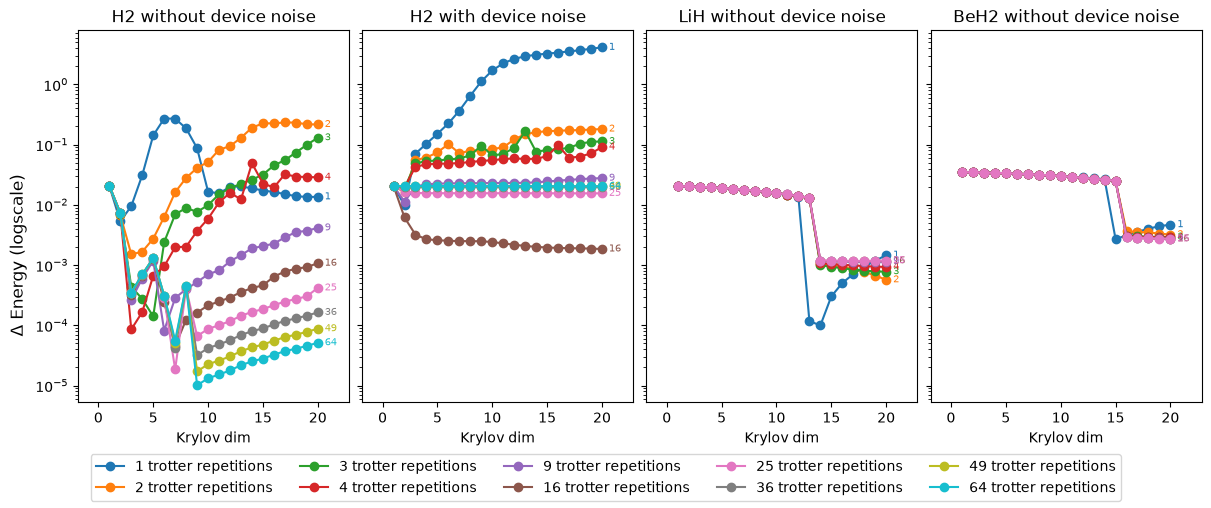

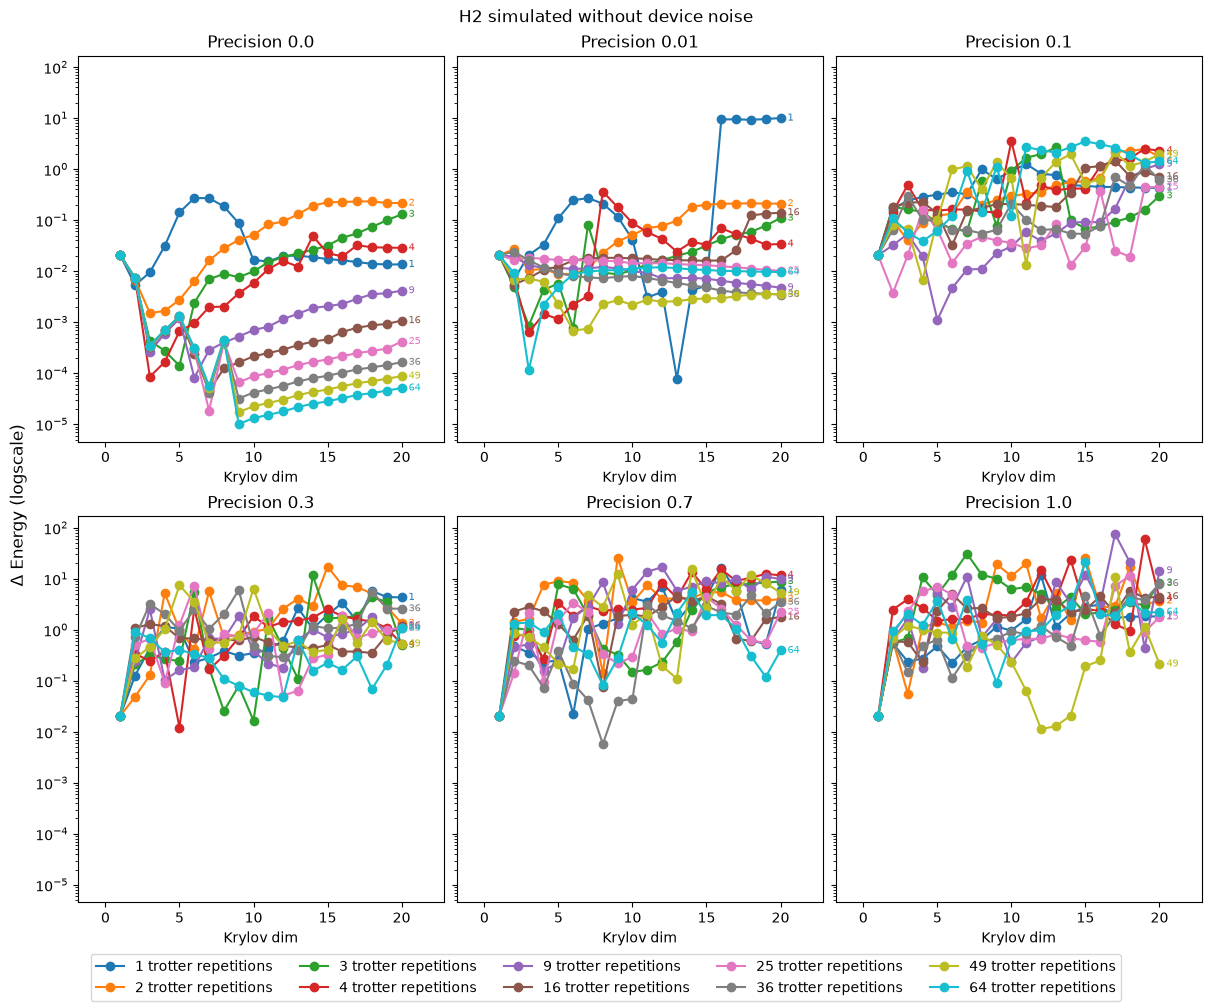

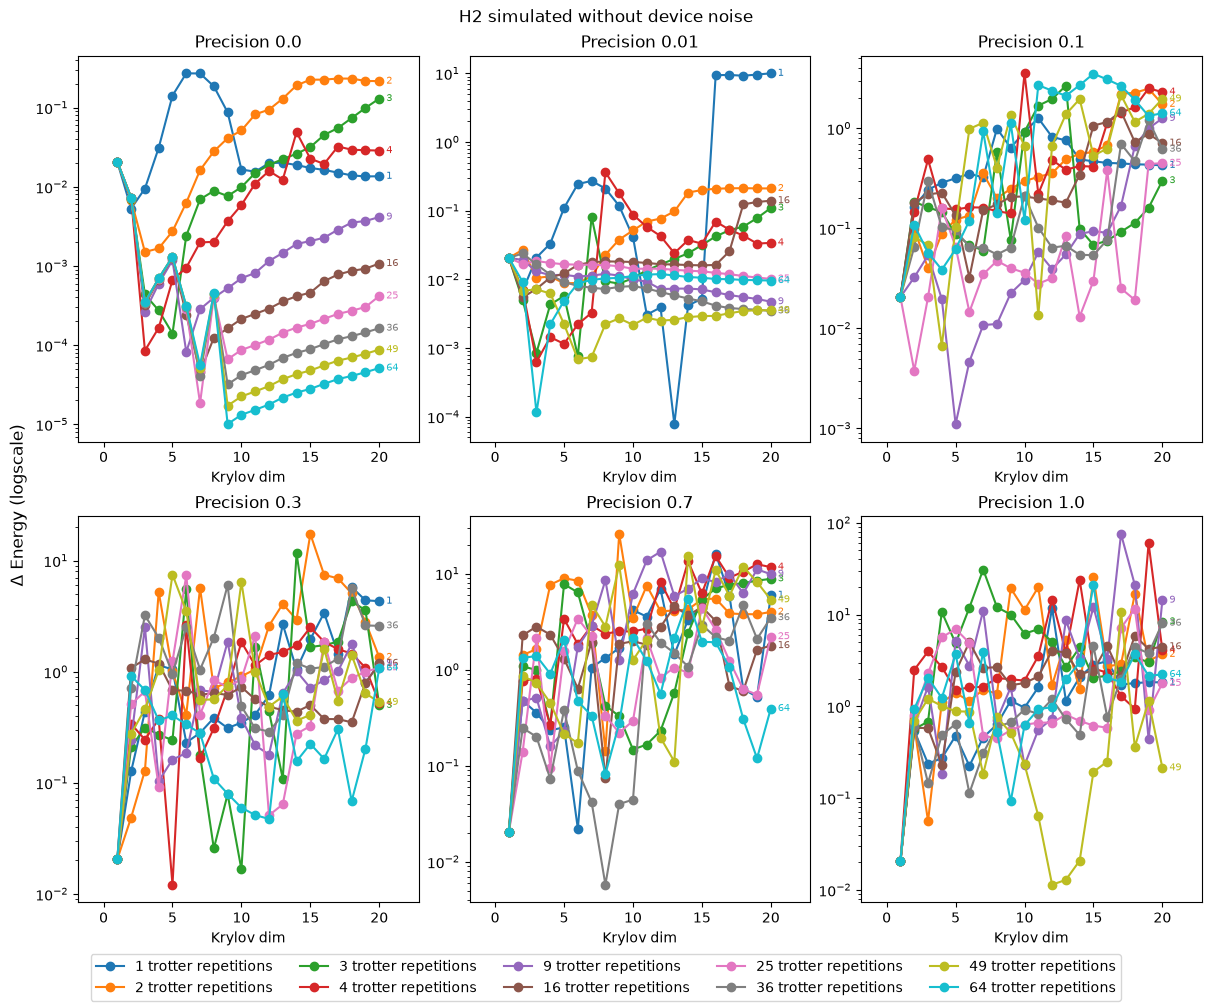

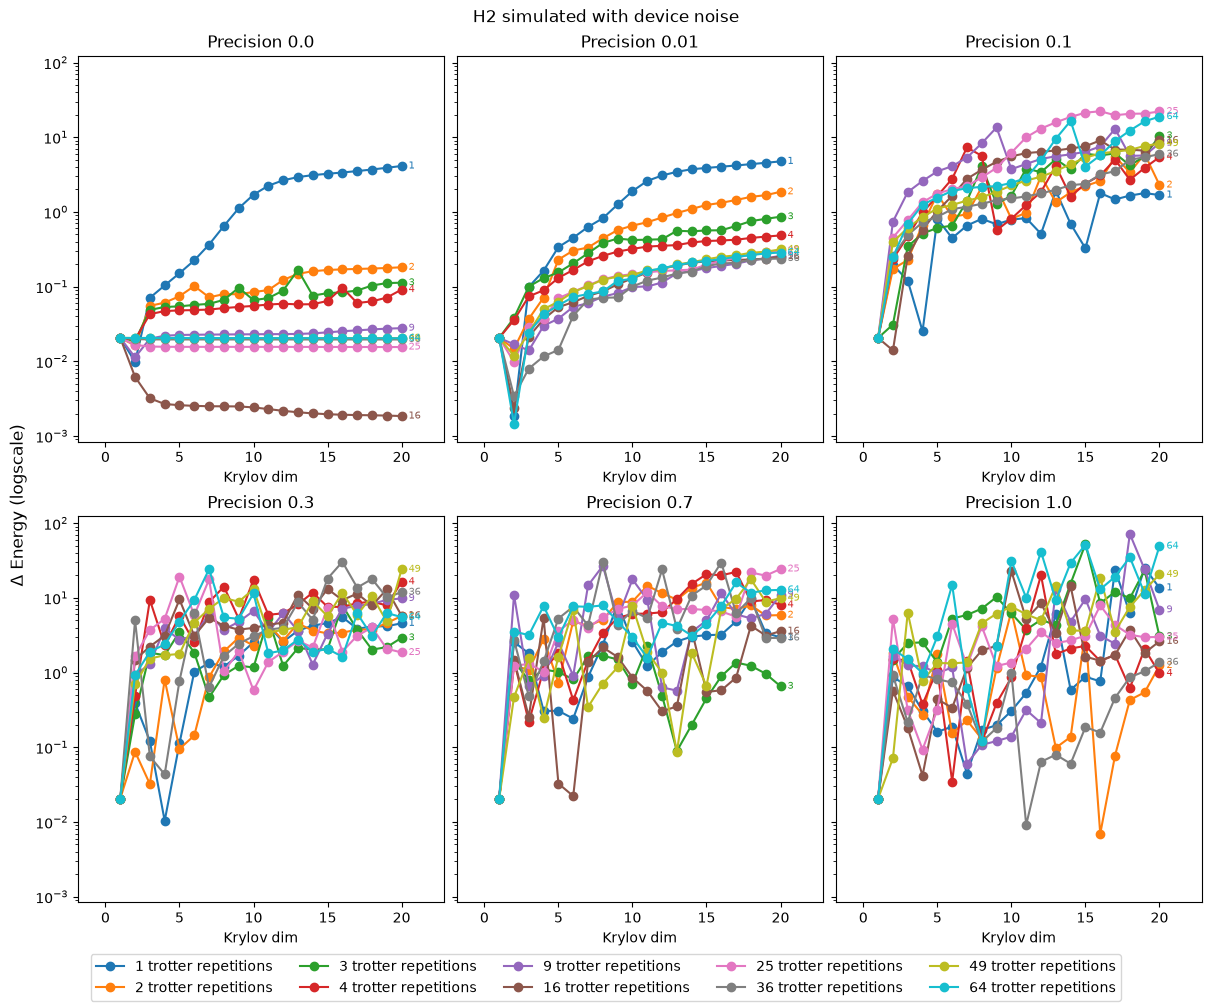

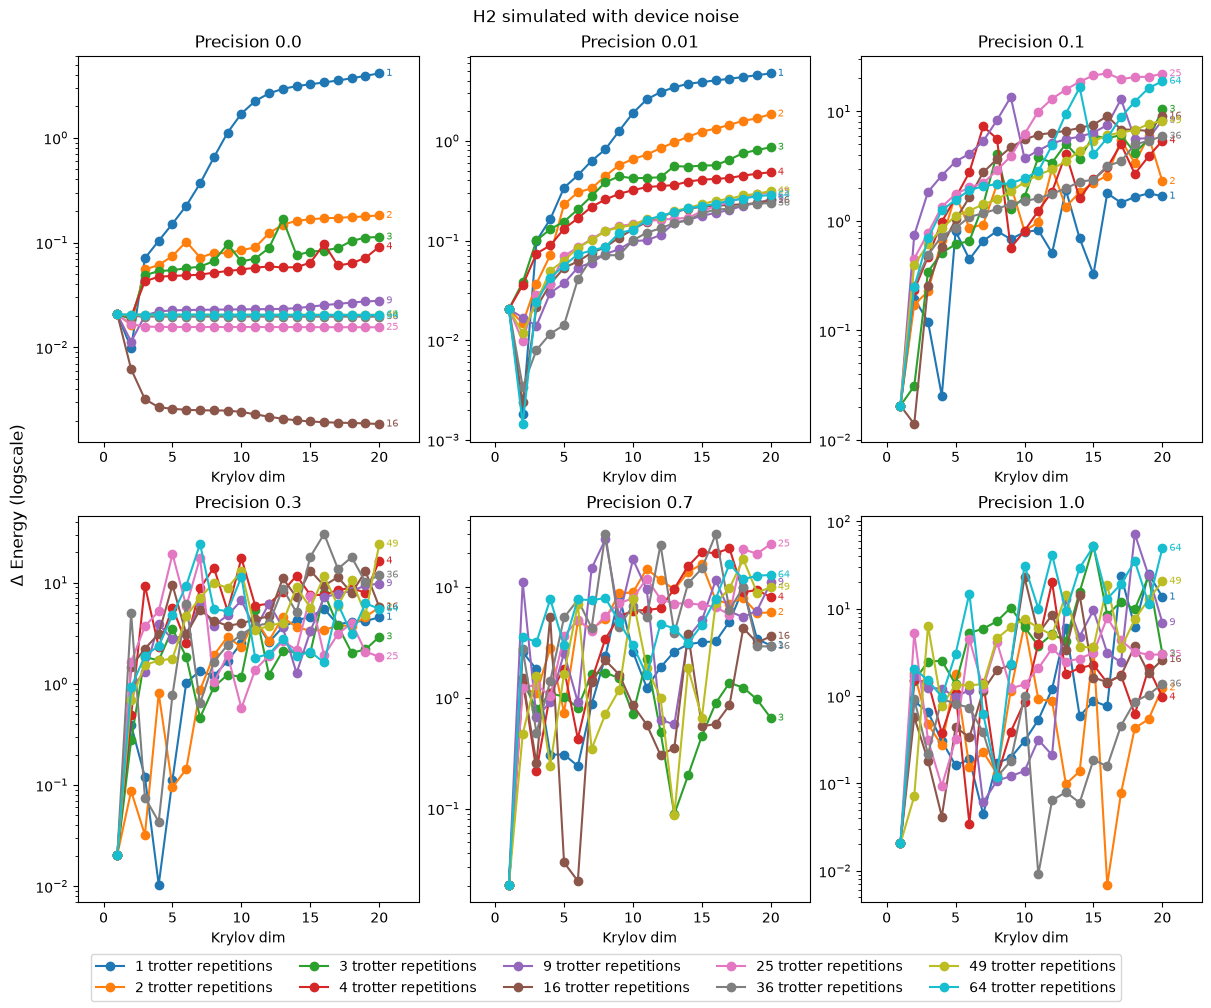

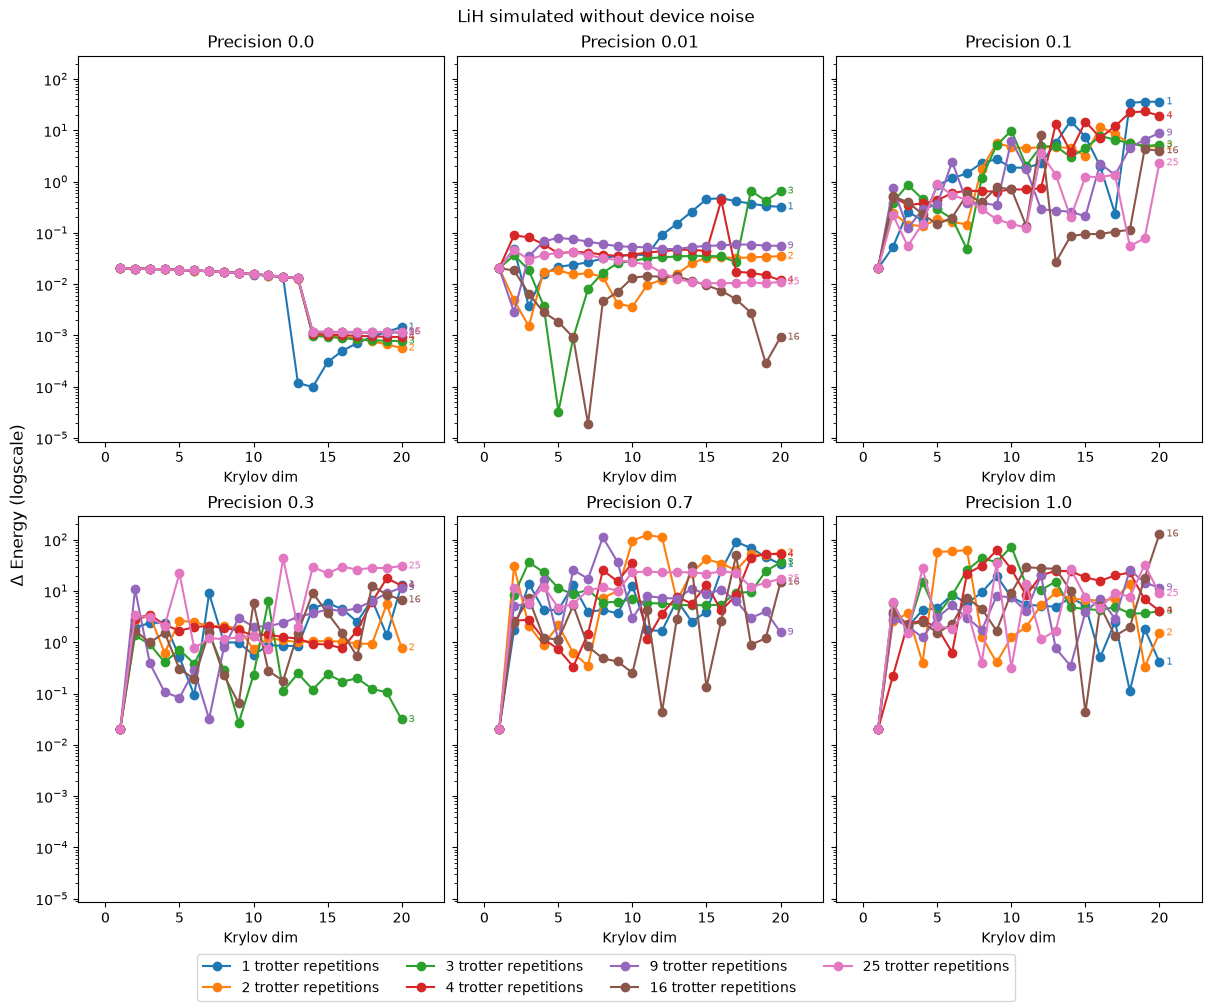

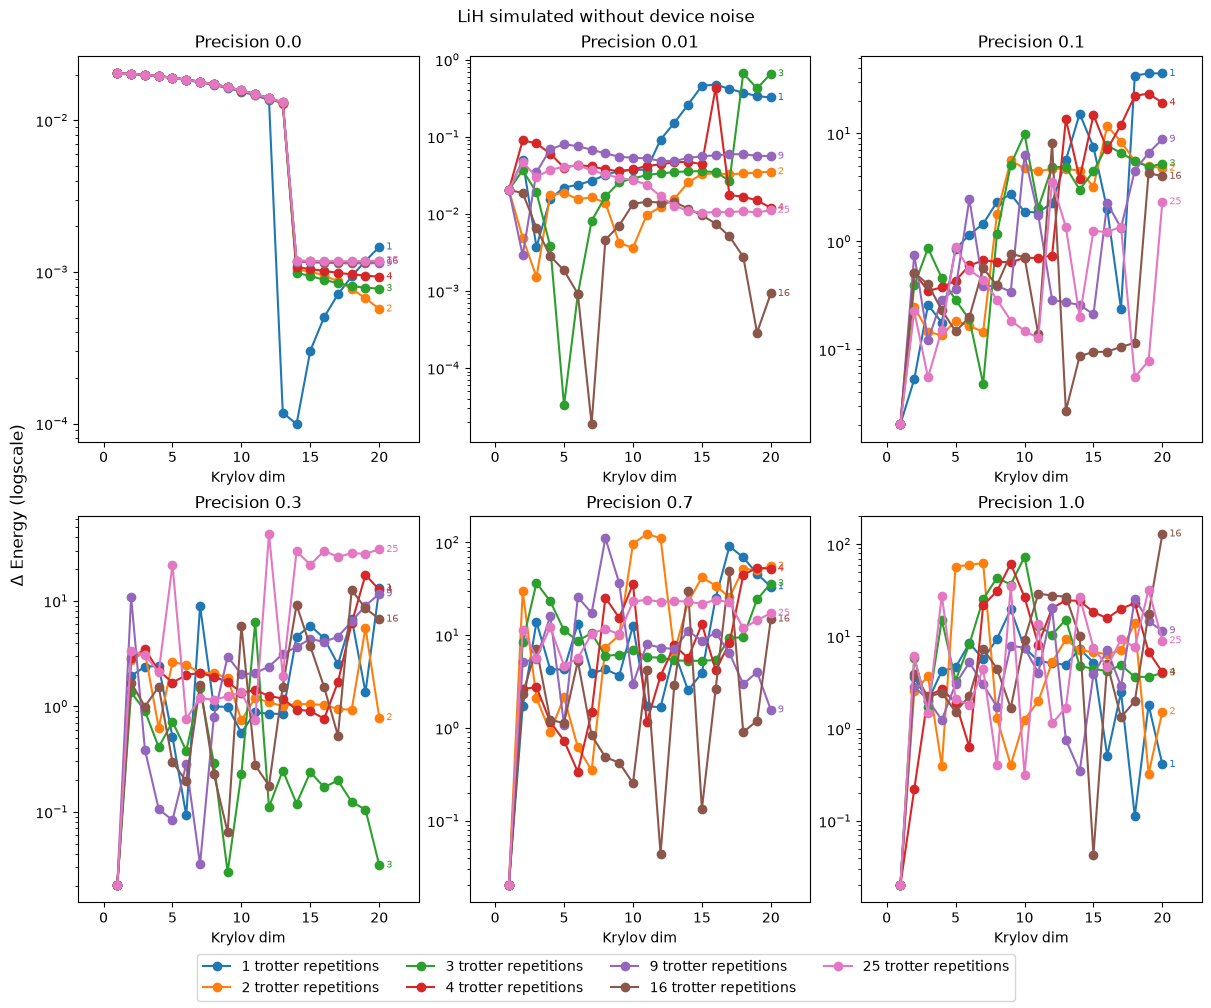

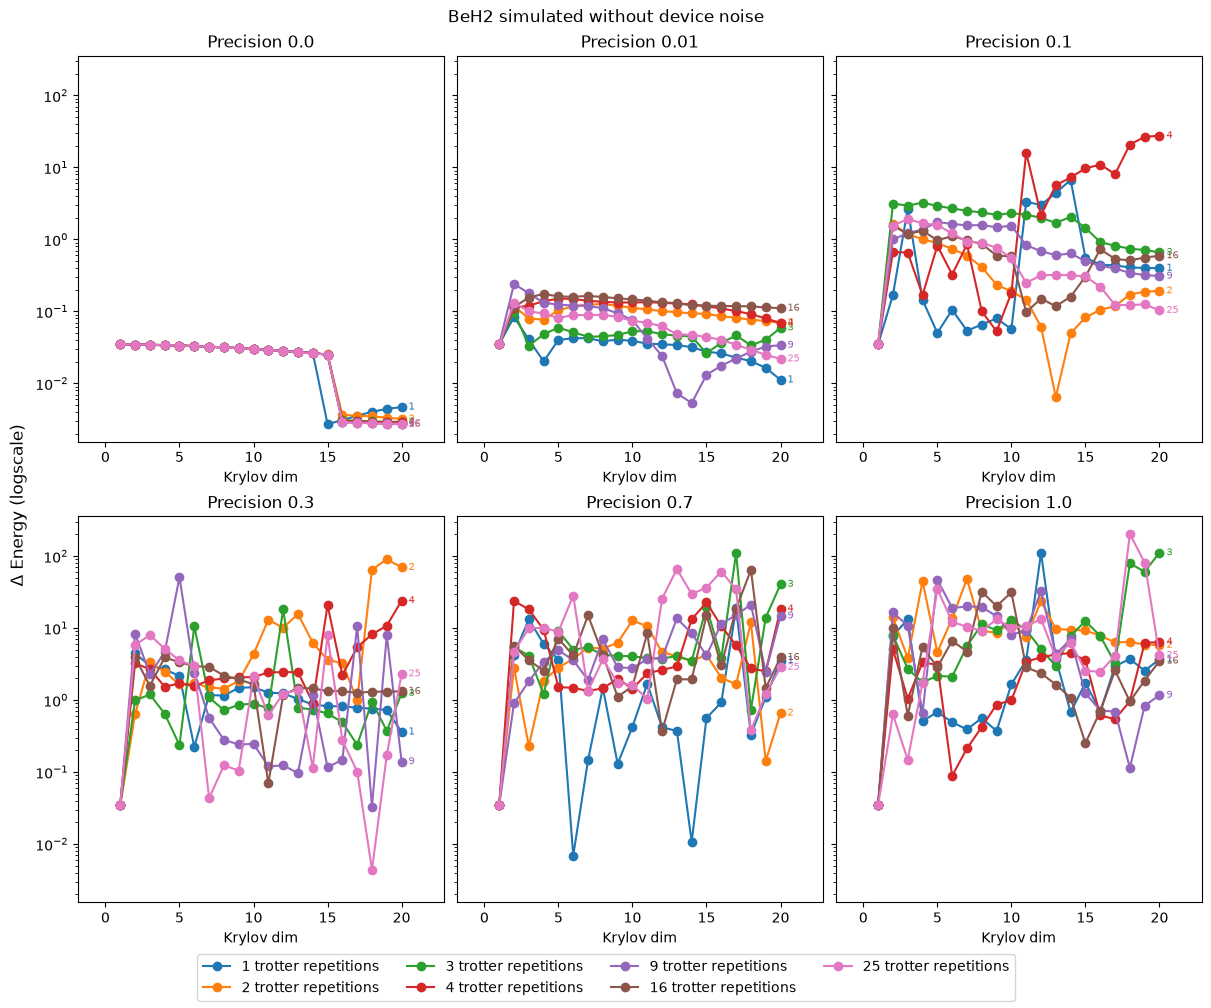

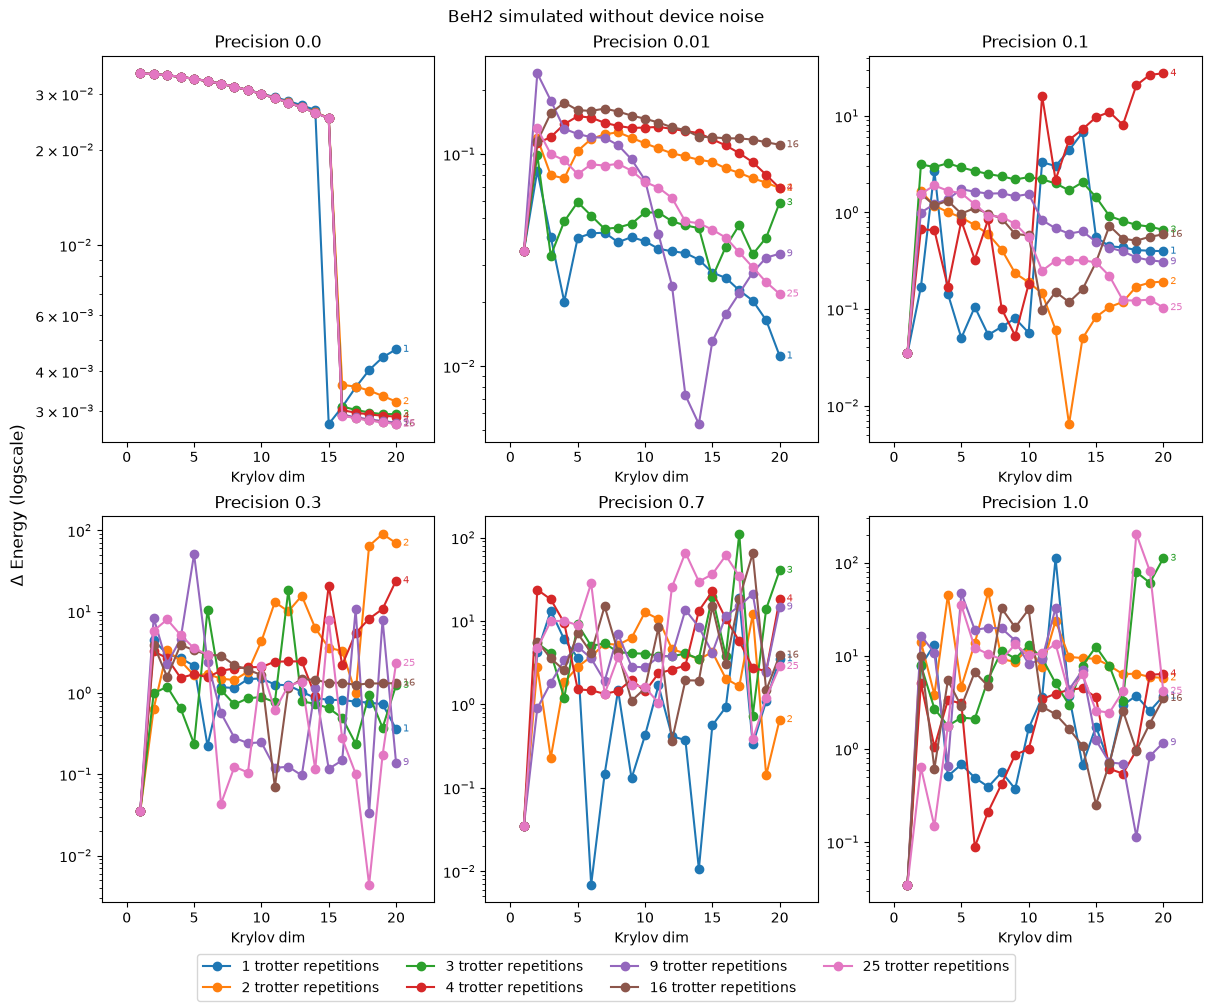

In [26]:
# Plots
# For various molecules observe convergence towards ground state energy at various number of trottter steps and possibly varying values of p
def convergence_plot(ax, molecule: str, K, P: float, T, backend_name: str, eigen_threshold: float, exact_ge: float, mol_in_title: bool = False):    
    ax.margins(x=0.15)
    for t in T: 
        try:
            energies: np.ndarray = load(molecule=molecule, K=K, P=P, T=t, eigen_threshold=eigen_threshold, backend_name=backend_name)
            line, = ax.semilogy(list(range(1, K + 1)), np.abs(energies - exact_ge), marker='o', label=f"{t} trotter repetitions")

            x, y = line.get_xdata(), line.get_ydata()
            ax.annotate(
                f"{t}",
                (x[-1], y[-1]),
                xytext=(5, 0),
                textcoords="offset points",
                va="center",
                color=line.get_color(),
                fontsize=7
            )
        except:
            print(f"Skipping molecule={molecule}, P={P}, T={t}, backend_name={backend_name}")

    ax.set_xlabel("Krylov dim")
    if mol_in_title:
        ax.set_title(f"{mol} {"with" if noisy else "without"} device noise")    
    else:
        ax.set_title(f"Precision {P}")


        

mol_combinations = [("H2", False), ("H2", True), ("LiH", False), ("BeH2", False)]
p_values = [0.0, 0.01, 0.1 , 0.3, 0.7, 1.0]

base_path = Path("../Latex/Figures/QSE/convergence_plots")

T_values = [1,2,3,4,9,16,25,36,49,64]
j = 0
p0fig, p0ax = plt.subplots(1, len(mol_combinations), figsize=(12, 5), layout="constrained", sharey=True)
for mol, noisy in mol_combinations:
    hamil = MolecularQubitHamiltonian(geometry_for_molecule(mol), basis="sto3g")
    fig_share, ax_share = plt.subplots(2, len(p_values) // 2, figsize=(12, 10), layout="constrained", sharey=True)
    fig_non_share, ax_non_share = plt.subplots(2, len(p_values) // 2, figsize=(12, 10), layout="constrained", sharey=False)
    figs = [(fig_share, ax_share, True), (fig_non_share, ax_non_share, False)]

    exact_ge = hamil.exact_ground_state_energy()
    backend_name = "simulated_ibm_fez" if noisy else "ideal"
    i = 0
    _T_values = T_values if mol == "H2" else T_values[:7]
    for p in p_values:
        for _, ax, _ in figs:
            convergence_plot(ax[i // (len(p_values) // 2), i % (len(p_values) // 2)], mol, K=20, P=p, T=_T_values, backend_name=backend_name , eigen_threshold=0.1, exact_ge=exact_ge)
        i += 1
        if p == 0.0:
            convergence_plot(p0ax[j], mol, K=20, P=p, T=_T_values, backend_name=backend_name , eigen_threshold=0.1, exact_ge=exact_ge, mol_in_title=True)
            j += 1

    for fig, ax, shares in figs:
        handles, labels = ax[0,0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="outside lower center", ncol=(len(_T_values) + 1)//2)
        fig.suptitle(f"{mol} simulated {"with" if noisy else "without"} device noise")
        fig.supylabel(r"$\Delta$ Energy (logscale)")

        fig_path = base_path / ("noisy" if noisy else "no-noise") / mol /  ("varying-trotter_share_y.png" if shares else "varying-trotter.png")
        fig_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(fig_path, dpi=300, bbox_inches="tight")

    
        fig.show()


#p0fig.suptitle(f"Precision 0.0")
p0fig.supylabel(r"$\Delta$ Energy (logscale)")
handles, labels = p0ax[0].get_legend_handles_labels()
p0fig.legend(handles, labels, loc="outside lower center", ncol=(len(T_values) + 1)//2)

p0fig_path = base_path / "p0.png"
p0fig.savefig(p0fig_path, dpi=300, bbox_inches="tight")
p0fig.show()

#path = Path(f"Latex/Figures/QSE/convergence_plot/{"no-noise" if backend_name == "ideal" else "noisy"}/{molecule}/varying-trotter.png")
#path.parent.mkdir(parents=True, exist_ok=True)
#p0fig.savefig(path, dpi=300, bbox_inches="tight")
